# Filtrado en el dominio de la frecuencia

**Procesamiento de Imágenes — Universidad Diego Portales**

En la clase anterior vimos que la FFT descompone una imagen en frecuencias y terminamos con el
**teorema de la convolución**:

$$\mathcal{F}\{f * h\} = F \cdot H$$

Este cuaderno lleva esa idea a la práctica. Todo filtrado en frecuencia sigue el mismo esquema:

$$f(x,y) \;\xrightarrow{\text{FFT}}\; F(u,v) \;\xrightarrow{\;\times H(u,v)\;}\; G(u,v) \;\xrightarrow{\text{IFFT}}\; g(x,y)$$

Contenido:

1. Equivalencia entre convolución y multiplicación (convolución circular, *padding*, simetría de $H$)
2. Filtros pasabajos: ideal, Butterworth y gaussiano
3. Filtros pasaaltos, Laplaciano y énfasis de altas frecuencias
4. Filtros pasabanda y rechazabanda
5. Filtros *notch* para ruido periódico
6. Filtro homomórfico
7. Actividad final

Las celdas marcadas con ✏️ están pensadas para que cambies parámetros, imágenes o agregues código.

## 0. Preparación

In [1]:
import os
import sys
import time
from functools import lru_cache

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal
from skimage import data, color, io, img_as_float
from skimage.metrics import peak_signal_noise_ratio as psnr
import ipywidgets as widgets
from ipywidgets import interact

plt.rcParams.update({"image.cmap": "gray", "axes.titlesize": 13, "font.size": 12})

# ---- Parámetros generales ----
CARPETA_IMAGENES = "imagenes"   # imágenes especiales de la clase
RUTA_ARCHIVO = None             # ✏️ p. ej. "mi_foto.jpg" para usar una imagen propia
GUARDAR_FIGURAS = False         # True guarda las figuras en CARPETA_FIGURAS (las usan las láminas)
CARPETA_FIGURAS = "figuras"


def guardar(fig, nombre):
    if GUARDAR_FIGURAS:
        os.makedirs(CARPETA_FIGURAS, exist_ok=True)
        fig.savefig(os.path.join(CARPETA_FIGURAS, nombre + ".png"), dpi=200, bbox_inches="tight")

**Solo en Google Colab:** la celda siguiente pide subir las imágenes de la carpeta `imagenes`
(los `.png` que acompañan este cuaderno). Si trabajas en tu computador, no hace nada.

In [2]:
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not os.path.isdir(CARPETA_IMAGENES):
    from google.colab import files
    os.makedirs(CARPETA_IMAGENES, exist_ok=True)
    for nombre, contenido in files.upload().items():
        with open(os.path.join(CARPETA_IMAGENES, nombre), "wb") as archivo:
            archivo.write(contenido)

### 0.1 Imágenes

`cargar(nombre)` acepta el nombre de una imagen de `skimage.data` (por ejemplo `"camera"`), el nombre
de un archivo de la carpeta `imagenes` o una ruta propia. Siempre devuelve una imagen en gris, `float`
en $[0, 1]$.

In [2]:
IMAGENES_SKIMAGE = {
    "camera": data.camera, "moon": data.moon, "astronaut": data.astronaut,
    "coffee": data.coffee, "chelsea": data.chelsea, "brick": data.brick,
    "grass": data.grass, "page": data.page, "text": data.text,
}


@lru_cache(maxsize=None)
def cargar(nombre):
    if nombre in IMAGENES_SKIMAGE:
        im = IMAGENES_SKIMAGE[nombre]()
    elif os.path.exists(os.path.join(CARPETA_IMAGENES, nombre)):
        im = io.imread(os.path.join(CARPETA_IMAGENES, nombre))
    else:
        im = io.imread(nombre)
    im = img_as_float(im)
    if im.ndim == 3:
        im = color.rgb2gray(im[..., :3])
    return im


def opciones_imagenes():
    # Lista para los menús de los controles interactivos
    nombres = list(IMAGENES_SKIMAGE)
    if os.path.isdir(CARPETA_IMAGENES):
        nombres += sorted(n for n in os.listdir(CARPETA_IMAGENES) if n.lower().endswith((".png", ".jpg", ".jpeg")))
    if RUTA_ARCHIVO:
        nombres = [RUTA_ARCHIVO] + nombres
    return nombres


print(opciones_imagenes())

['camera', 'moon', 'astronaut', 'coffee', 'chelsea', 'brick', 'grass', 'page', 'text', 'actividad_ruido.png', 'bloques_borde.png', 'iluminacion_no_uniforme.png', 'ruido_anillo.png', 'ruido_periodico.png']


### 0.2 Herramientas de frecuencia

- `fft_centrada(f)`: FFT 2D con la frecuencia cero (DC) al centro.
- `espectro(F)`: $\log(1+|F|)$ para visualizar.
- `frecuencias(forma)`: matrices $U, V$ con la frecuencia de cada punto del espectro centrado, en
  **ciclos por imagen** (el centro es $(0,0)$). La distancia al centro es $D(u,v)=\sqrt{u^2+v^2}$.
- `filtrar(f, H_fun, padding, **param)`: aplica todo el esquema FFT → $H\cdot F$ → IFFT.
  `H_fun` es cualquier función que reciba `U, V` y los parámetros del filtro.

In [4]:
def fft_centrada(f):
    return np.fft.fftshift(np.fft.fft2(f))


def ifft_centrada(F):
    return np.fft.ifft2(np.fft.ifftshift(F))


def espectro(F):
    return np.log1p(np.abs(F))


def frecuencias(forma, forma_original=None):
    # U, V en ciclos por imagen. Si la imagen fue rellenada (padding), se miden en la
    # escala de la imagen original para que D0 signifique lo mismo con y sin padding.
    P, Q = forma
    M, N = forma_original or forma
    u = (np.arange(Q) - Q // 2) * N / Q
    v = (np.arange(P) - P // 2) * M / P
    return np.meshgrid(u, v)


def rellenar(f, padding):
    # Duplica el tamaño agregando M/2 y N/2 a cada lado ("ceros" o "reflejo")
    if padding == "ninguno":
        return f
    M, N = f.shape
    modo = {"ceros": "constant", "reflejo": "symmetric"}[padding]
    return np.pad(f, ((M // 2, M - M // 2), (N // 2, N - N // 2)), mode=modo)


def filtrar(f, H_fun, padding="reflejo", detalles=False, **param):
    M, N = f.shape
    fp = rellenar(f, padding)
    U, V = frecuencias(fp.shape, f.shape)
    F = fft_centrada(fp)
    H = H_fun(U, V, **param)
    G = H * F
    g = ifft_centrada(G)
    if padding != "ninguno":
        g = g[M // 2:M // 2 + M, N // 2:N // 2 + N]
    if detalles:
        return g.real, {"F": F, "H": H, "G": G, "imag_max": np.abs(g.imag).max()}
    return g.real


def normalizar(g, recorte=0):
    # Lleva g a [0, 1]. Con recorte > 0 ignora ese % de valores extremos en cada lado.
    lo, hi = np.percentile(g, [recorte, 100 - recorte])
    return np.clip((g - lo) / (hi - lo + 1e-12), 0, 1)


def ver(imagenes, titulos, cmaps=None, figsize=None, vmin=None, vmax=None, columnas=None):
    # Muestra una fila (o grilla) de imágenes y devuelve la figura
    n = len(imagenes)
    columnas = columnas or n
    filas = int(np.ceil(n / columnas))
    figsize = figsize or (3.3 * columnas, 3.4 * filas)
    fig, ax = plt.subplots(filas, columnas, figsize=figsize, squeeze=False)
    for a in ax.ravel():
        a.axis("off")
    for k, (im, t) in enumerate(zip(imagenes, titulos)):
        a = ax.ravel()[k]
        cmap = (cmaps[k] if isinstance(cmaps, list) else cmaps) or "gray"
        a.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
        a.set_title(t)
    fig.tight_layout()
    return fig

---
## 1. Equivalencia: convolución en el espacio = multiplicación en la frecuencia

### 1.1 El problema: la DFT “ve” señales periódicas

La DFT de $N$ muestras supone que la señal **se repite cada $N$ muestras**. Por eso, multiplicar
DFT y volver al espacio no entrega la convolución lineal que hicimos en clases, sino la
**convolución circular**:

$$(f \circledast h)[n] = \sum_{k=0}^{N-1} f[k]\; h[(n-k) \bmod N]$$

El índice $\bmod N$ significa que, cuando el kernel se sale por un extremo, **vuelve a entrar por el
otro** (como un reloj). El teorema exacto en el caso discreto es:

$$\text{DFT}\{f \circledast h\} = F \cdot H$$

Veamos un ejemplo pequeño, que se puede hacer a mano:
$f = [1, 2, 3, 4, 5, 6]$ y $h = [1, 1, 1]$.

In [5]:
f1 = np.array([1, 2, 3, 4, 5, 6], dtype=float)
h1 = np.array([1, 1, 1], dtype=float)

lineal = np.convolve(f1, h1)                                   # largo 6 + 3 - 1 = 8
circular = np.real(np.fft.ifft(np.fft.fft(f1) * np.fft.fft(h1, n=6)))
L = len(f1) + len(h1) - 1
con_padding = np.real(np.fft.ifft(np.fft.fft(f1, n=L) * np.fft.fft(h1, n=L)))

print("Convolución lineal        :", lineal)
print("FFT sin padding (N=6)     :", np.round(circular, 6))
print("FFT con padding (N=8)     :", np.round(con_padding, 6))

Convolución lineal        : [ 1.  3.  6.  9. 12. 15. 11.  6.]
FFT sin padding (N=6)     : [12.  9.  6.  9. 12. 15.]
FFT con padding (N=8)     : [ 1.  3.  6.  9. 12. 15. 11.  6.]


Las dos últimas muestras de la convolución lineal (11 y 6) **no caben** en 6 muestras: se doblan sobre
el inicio, $1+11=12$ y $3+6=9$. Este error se llama *wrap-around*.

**Solución:** rellenar con ceros (*zero padding*) hasta un largo $P \ge A + B - 1$, donde $A$ y $B$ son
los largos de la señal y del kernel. Así la parte que “da la vuelta” cae sobre ceros.

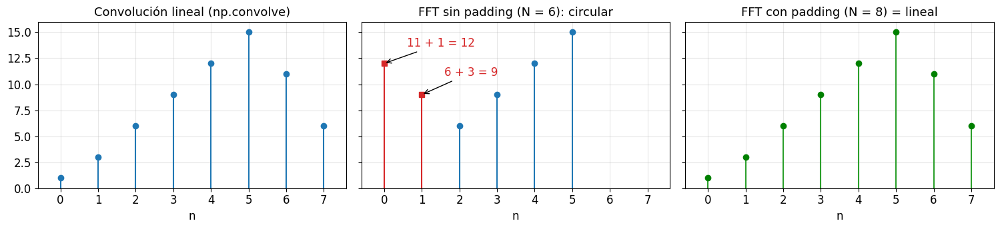

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
ax[0].stem(np.arange(8), lineal, basefmt=" ")
ax[0].set_title("Convolución lineal (np.convolve)")
colores = ["tab:red", "tab:red", "tab:blue", "tab:blue", "tab:blue", "tab:blue"]
for n, (y, c) in enumerate(zip(circular, colores)):
    ax[1].stem([n], [y], linefmt=c, markerfmt="o" if c == "tab:blue" else "s", basefmt=" ")
ax[1].set_title("FFT sin padding (N = 6): circular")
ax[1].annotate("11 + 1 = 12", (0, 12), (0.6, 13.6), arrowprops=dict(arrowstyle="->"), color="tab:red")
ax[1].annotate("6 + 3 = 9", (1, 9), (1.6, 10.8), arrowprops=dict(arrowstyle="->"), color="tab:red")
ax[2].stem(np.arange(8), con_padding, linefmt="tab:green", markerfmt="go", basefmt=" ")
ax[2].set_title("FFT con padding (N = 8) = lineal")
for a in ax:
    a.set_xlim(-0.6, 7.6)
    a.set_ylim(0, 16)
    a.set_xlabel("n")
    a.grid(alpha=0.3)
fig.tight_layout()
guardar(fig, "eq_1d_circular")
plt.show()

**¿Por qué pasa esto?** Para la DFT, $f$ es solo un periodo de una señal infinita y periódica.
Al deslizar el kernel por el borde, en vez de encontrar ceros encuentra **la copia vecina** de la señal.

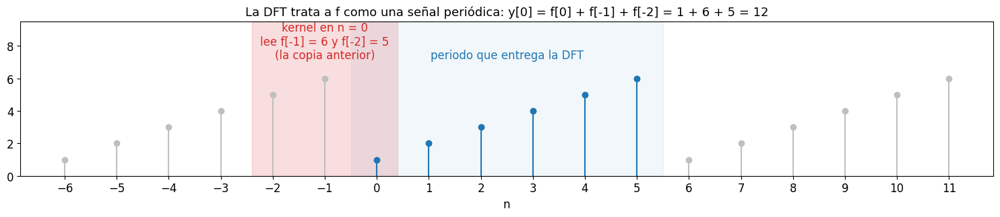

In [7]:
fig, ax = plt.subplots(figsize=(15, 3.4))
n = np.arange(-6, 12)
ax.stem(n, np.tile(f1, 3), linefmt="0.75", markerfmt="o", basefmt=" ")
ax.stem(np.arange(6), f1, linefmt="tab:blue", markerfmt="o", basefmt=" ")
ax.axvspan(-2.4, 0.4, color="tab:red", alpha=0.15)
ax.text(-1, 7.2, "kernel en n = 0\nlee f[-1] = 6 y f[-2] = 5\n(la copia anterior)", ha="center", color="tab:red")
ax.axvspan(-0.5, 5.5, color="tab:blue", alpha=0.06)
ax.text(2.5, 7.2, "periodo que entrega la DFT", ha="center", color="tab:blue")
ax.set_ylim(0, 9.5)
ax.set_xticks(n)
ax.set_xlabel("n")
ax.set_title("La DFT trata a f como una señal periódica: y[0] = f[0] + f[-1] + f[-2] = 1 + 6 + 5 = 12")
fig.tight_layout()
guardar(fig, "eq_1d_periodica")
plt.show()

### 1.2 Lo mismo en 2D

En una imagen el *wrap-around* ocurre en ambos ejes: el borde inferior “contamina” al superior y el
derecho al izquierdo. Comparamos tres caminos con un kernel promedio de $31 \times 31$:

| Camino | Equivale a |
|---|---|
| `ndimage.convolve(..., mode="wrap")` | convolución circular en el espacio |
| FFT **sin** padding | convolución circular |
| FFT **con** padding de ceros a $(M+m-1)\times(N+n-1)$ | convolución lineal (`mode="constant"`) |

In [9]:
def conv_fft(f, h, padding=True):
    # Convolución de f con el kernel h usando FFT. Devuelve una imagen del tamaño de f.
    M, N = f.shape
    m, n = h.shape
    P, Q = (M + m - 1, N + n - 1) if padding else (M, N)
    g = np.real(np.fft.ifft2(np.fft.fft2(f, s=(P, Q)) * np.fft.fft2(h, s=(P, Q))))
    if padding:
        return g[m // 2:m // 2 + M, n // 2:n // 2 + N]
    return np.roll(g, (-(m // 2), -(n // 2)), axis=(0, 1))   # el kernel tiene su centro en (m//2, n//2)


bloques = cargar("bloques_borde.png")
caja = np.ones((31, 31)) / 31**2

esp_lineal = ndimage.convolve(bloques, caja, mode="constant")
esp_wrap = ndimage.convolve(bloques, caja, mode="wrap")
fft_sin = conv_fft(bloques, caja, padding=False)
fft_con = conv_fft(bloques, caja, padding=True)

print(f"|FFT sin padding - espacial wrap    | máx = {np.abs(fft_sin - esp_wrap).max():.2e}")
print(f"|FFT con padding - espacial constant| máx = {np.abs(fft_con - esp_lineal).max():.2e}")
print(f"|FFT sin padding - espacial constant| máx = {np.abs(fft_sin - esp_lineal).max():.2e}  <- error del wrap-around")

|FFT sin padding - espacial wrap    | máx = 1.84e-14
|FFT con padding - espacial constant| máx = 1.87e-14
|FFT sin padding - espacial constant| máx = 4.84e-01  <- error del wrap-around


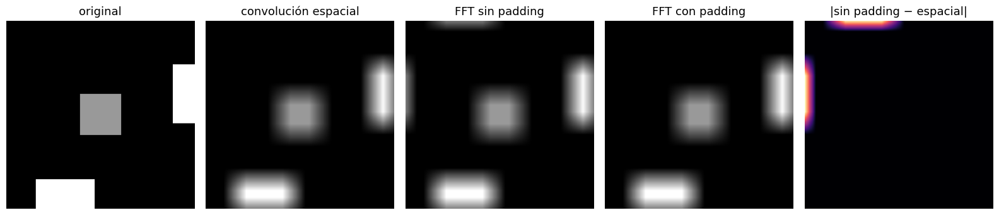

In [10]:
fig = ver([bloques, esp_lineal, fft_sin, fft_con, np.abs(fft_sin - esp_lineal)],
          ["original", "convolución espacial", "FFT sin padding", "FFT con padding", "|sin padding − espacial|"],
          cmaps=["gray", "gray", "gray", "gray", "magma"], figsize=(16, 3.8))
guardar(fig, "eq_2d_bloques")
plt.show()

Con la FFT sin padding aparece luz arriba (que viene del bloque inferior) y a la izquierda (que viene
del bloque derecho). En una imagen real el efecto es el mismo, pero más difícil de notar:

cameraman: máx |con padding - espacial| = 1.64e-14


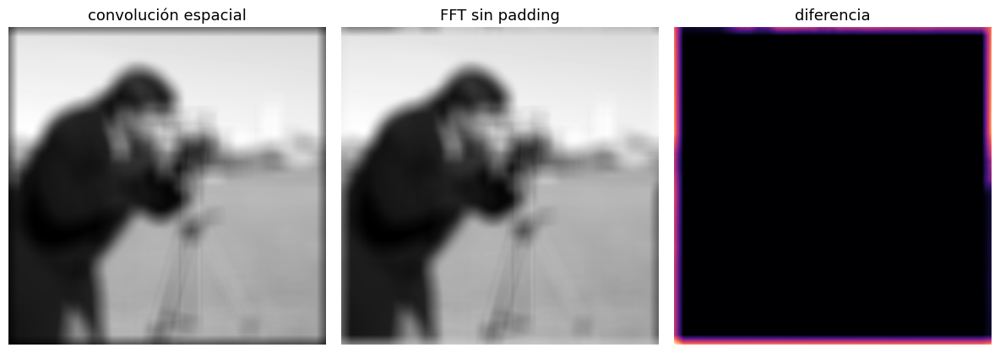

In [11]:
cam = cargar("camera")
cam_lineal = ndimage.convolve(cam, caja, mode="constant")
cam_sin = conv_fft(cam, caja, padding=False)
cam_con = conv_fft(cam, caja, padding=True)
print(f"cameraman: máx |con padding - espacial| = {np.abs(cam_con - cam_lineal).max():.2e}")

fig = ver([cam_lineal, cam_sin, np.abs(cam_sin - cam_lineal)],
          ["convolución espacial", "FFT sin padding", "diferencia"],
          cmaps=["gray", "gray", "magma"], figsize=(12, 4.2))
guardar(fig, "eq_2d_camera")
plt.show()

### 1.3 Cada kernel tiene su “huella” en frecuencia

Como $g = f * h \Leftrightarrow G = F\cdot H$, la transformada del kernel, $H = \mathcal{F}\{h\}$, dice
**cuánto deja pasar de cada frecuencia**. Los kernels de las clases 7 y 8 se ven así (FFT con padding a
$128\times128$):

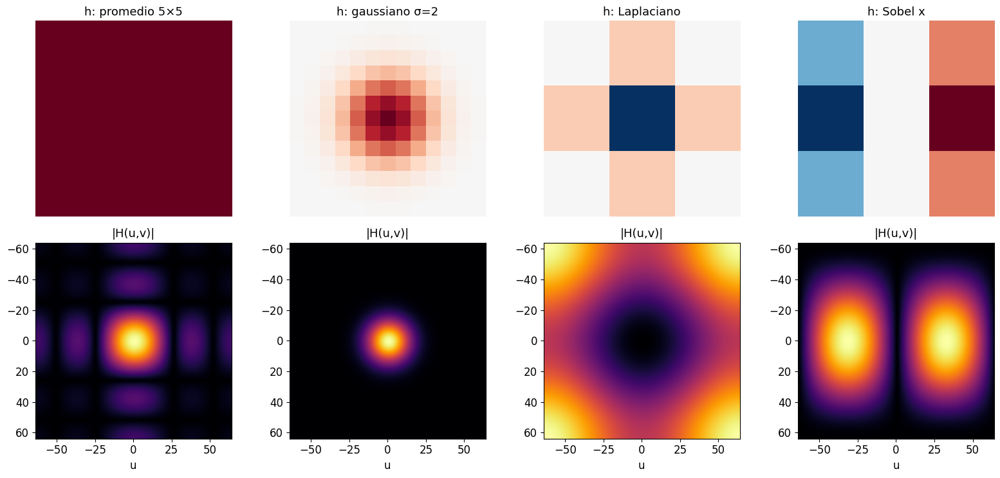

In [12]:
def kernel_gauss(sigma):
    r = int(np.ceil(3 * sigma))
    x = np.arange(-r, r + 1)
    g = np.exp(-x**2 / (2 * sigma**2))
    k = np.outer(g, g)
    return k / k.sum()


KERNELS = {
    "promedio 5×5": np.ones((5, 5)) / 25,
    "gaussiano σ=2": kernel_gauss(2),
    "Laplaciano": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], float),
    "Sobel x": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
}

fig, ax = plt.subplots(2, 4, figsize=(16, 7.6))
for j, (nombre, k) in enumerate(KERNELS.items()):
    ax[0, j].imshow(k, cmap="RdBu_r", vmin=-np.abs(k).max(), vmax=np.abs(k).max())
    ax[0, j].set_title(f"h: {nombre}")
    Hk = np.fft.fftshift(np.fft.fft2(k, s=(128, 128)))
    ax[1, j].imshow(np.abs(Hk), cmap="inferno", extent=[-64, 64, 64, -64])
    ax[1, j].set_title("|H(u,v)|")
    ax[1, j].set_xlabel("u")
for a in ax[0]:
    a.axis("off")
fig.tight_layout()
guardar(fig, "eq_kernels_frecuencia")
plt.show()

- **Promedio:** $|H|$ es una *sinc* 2D. Deja pasar las bajas frecuencias, pero tiene **lóbulos
  laterales**: no es un pasabajos limpio.
- **Gaussiano:** su transformada es **otra gaussiana**, sin lóbulos. Por eso suaviza sin artefactos.
- **Laplaciano:** vale 0 en el centro (anula la DC, es decir, el brillo medio) y crece hacia afuera:
  es un **pasaaltos**.
- **Sobel:** pasaaltos **direccional**: anula la columna $u=0$ y responde a cambios horizontales.

**Gaussiano en el espacio ⇔ gaussiano en frecuencia.** Un kernel gaussiano de desviación $\sigma$
(píxeles) equivale a $H(u,v)=e^{-D^2/2D_0^2}$ con $D_0 = \dfrac{N}{2\pi\sigma}$ (en ciclos por imagen):

σ = 4 px  ->  D0 = 20.4 ciclos/imagen
Diferencia máxima entre ambos caminos: 9.0e-10


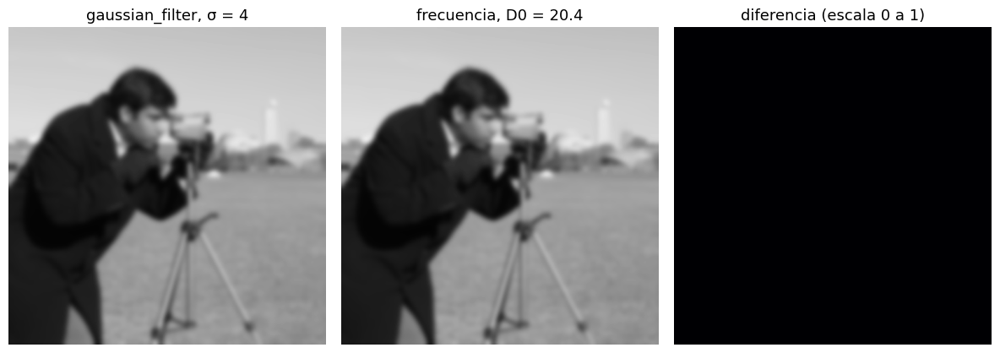

In [13]:
def pb_gauss(U, V, D0, n=None):
    return np.exp(-(U**2 + V**2) / (2 * D0**2))


sigma = 4
D0_equivalente = cam.shape[0] / (2 * np.pi * sigma)
g_espacio = ndimage.gaussian_filter(cam, sigma, mode="reflect", truncate=6)
g_frecuencia = filtrar(cam, pb_gauss, padding="reflejo", D0=D0_equivalente)

print(f"σ = {sigma} px  ->  D0 = {D0_equivalente:.1f} ciclos/imagen")
print(f"Diferencia máxima entre ambos caminos: {np.abs(g_espacio - g_frecuencia).max():.1e}")

fig = ver([g_espacio, g_frecuencia, np.abs(g_espacio - g_frecuencia)],
          [f"gaussian_filter, σ = {sigma}", f"frecuencia, D0 = {D0_equivalente:.1f}", "diferencia (escala 0 a 1)"],
          cmaps=["gray", "gray", "magma"], figsize=(12, 4.2), vmin=0, vmax=1)
guardar(fig, "eq_gauss_espacio_frecuencia")
plt.show()

### 1.4 ¿Cuándo conviene la FFT?

La convolución directa cuesta del orden de $MN \cdot m n$ operaciones (crece con el **área del
kernel**); la vía FFT cuesta del orden de $MN\log(MN)$ y **casi no depende del tamaño del kernel**.

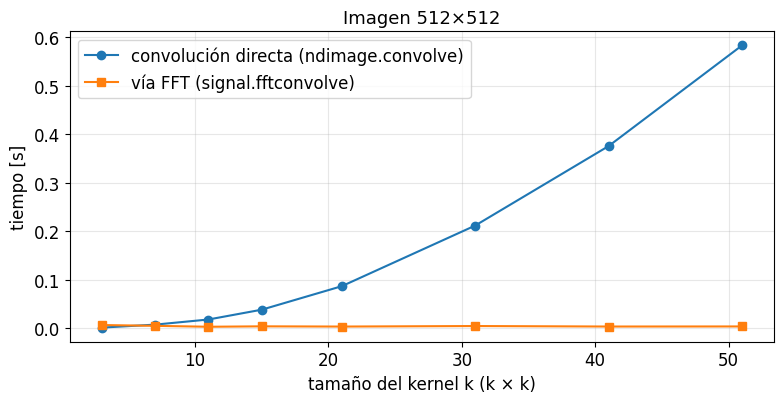

In [14]:
tamanos = [3, 7, 11, 15, 21, 31, 41, 51]
t_espacio, t_fft = [], []
for k in tamanos:
    h = np.ones((k, k)) / k**2
    t0 = time.perf_counter()
    ndimage.convolve(cam, h, mode="constant")
    t_espacio.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    signal.fftconvolve(cam, h, mode="same")
    t_fft.append(time.perf_counter() - t0)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(tamanos, t_espacio, "o-", label="convolución directa (ndimage.convolve)")
ax.plot(tamanos, t_fft, "s-", label="vía FFT (signal.fftconvolve)")
ax.set_xlabel("tamaño del kernel k (k × k)")
ax.set_ylabel("tiempo [s]")
ax.set_title(f"Imagen {cam.shape[0]}×{cam.shape[1]}")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
guardar(fig, "eq_tiempos")
plt.show()

### 1.5 ¿Por qué $H$ debe ser real y simétrico?

Escribamos cada coeficiente como magnitud y fase: $F = |F|e^{j\phi}$. Al multiplicar,

$$G = H\cdot F = |H|\,|F|\;e^{j(\phi + \angle H)}$$

- La **fase** guarda **dónde** están las cosas en la imagen (recuerda la propiedad de traslación).
  Si $H$ es **real y positivo**, $\angle H = 0$: el filtro cambia cuánto pesa cada frecuencia, pero **no
  mueve nada**. A estos filtros se les llama de **fase cero**.
- Una imagen real cumple $F(-u,-v) = F^*(u,v)$ (simetría hermitiana). Para que $g$ también sea real,
  $G$ debe conservar esa simetría, lo que exige $H(-u,-v) = H^*(u,v)$. Si $H$ es real, esto se reduce a
  $H(-u,-v) = H(u,v)$: **simétrico respecto del centro**.
- Por eso todos los filtros de esta clase dependen solo de la distancia $D(u,v)$ al centro, o vienen
  en **pares simétricos** (los *notch*).

Lo comprobamos con tres filtros: uno real y simétrico, uno no simétrico y uno con fase lineal.

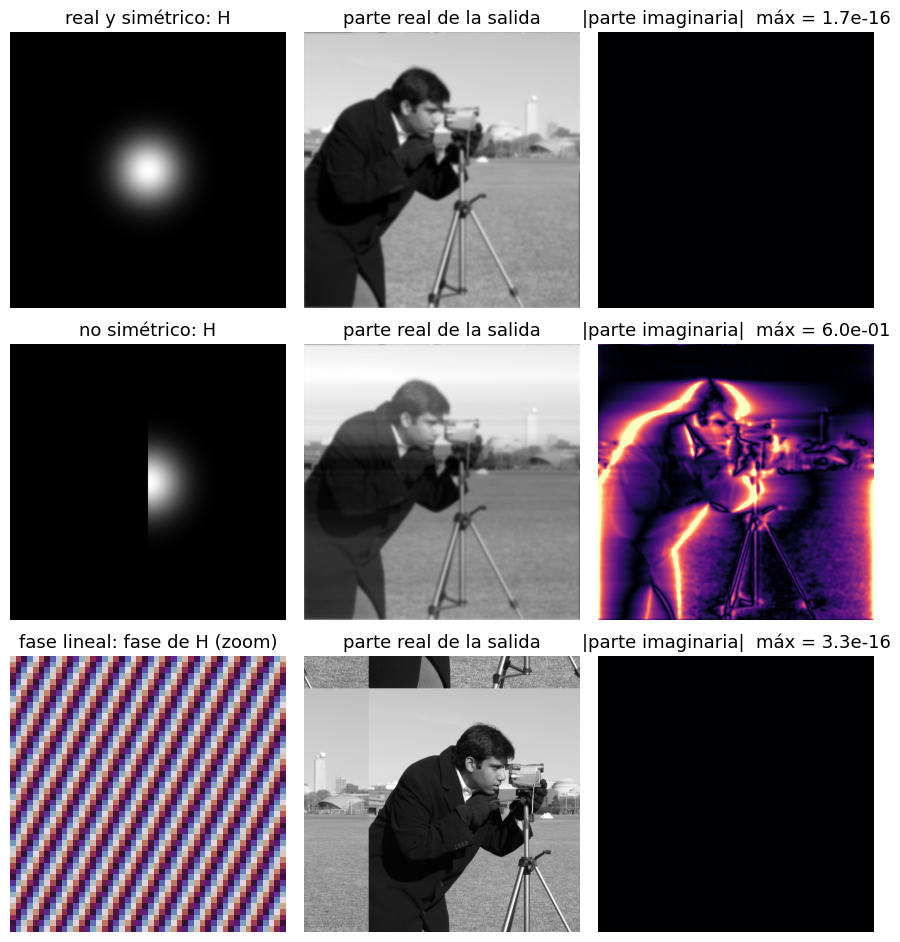

In [15]:
def H_asimetrico(U, V, D0):
    return pb_gauss(U, V, D0) * (U >= 0)          # solo la mitad derecha del espectro


def H_fase_lineal(U, V, dx, dy):
    M, N = U.shape
    return np.exp(-2j * np.pi * (U * dx / N + V * dy / M))   # |H| = 1, solo cambia la fase


casos = [
    ("real y simétrico", pb_gauss, dict(D0=40)),
    ("no simétrico", H_asimetrico, dict(D0=40)),
    ("fase lineal", H_fase_lineal, dict(dx=120, dy=60)),
]
fig, ax = plt.subplots(3, 3, figsize=(9, 9.6))
for i, (nombre, Hf, p) in enumerate(casos):
    g, info = filtrar(cam, Hf, padding="ninguno", detalles=True, **p)
    salida = ifft_centrada(info["G"])
    if np.iscomplexobj(info["H"]):
        c = cam.shape[0] // 2
        ax[i, 0].imshow(np.angle(info["H"])[c - 24:c + 24, c - 24:c + 24], cmap="twilight")
        ax[i, 0].set_title(f"{nombre}: fase de H (zoom)")
    else:
        ax[i, 0].imshow(info["H"], cmap="gray")
        ax[i, 0].set_title(f"{nombre}: H")
    ax[i, 1].imshow(salida.real, cmap="gray")
    ax[i, 1].set_title("parte real de la salida")
    ax[i, 2].imshow(np.abs(salida.imag), cmap="magma", vmin=0, vmax=0.3)
    ax[i, 2].set_title(f"|parte imaginaria|  máx = {info['imag_max']:.1e}")
for a in ax.ravel():
    a.axis("off")
fig.tight_layout()
guardar(fig, "eq_simetria")
plt.show()

1. **Real y simétrico:** la parte imaginaria es del orden de $10^{-16}$ (error numérico). Se descarta
   con `np.real` sin perder nada.
2. **No simétrico:** la salida tiene una parte imaginaria grande. Tomar `np.real` en este caso **esconde
   un error de diseño**.
3. **Fase lineal:** $|H|=1$, así que no cambia ninguna magnitud, pero la imagen **se traslada**
   (y da la vuelta por los bordes, porque la DFT es circular). La fase es posición.

> **Regla práctica:** antes de descartar la parte imaginaria, verifica que sea despreciable
> (`detalles=True` en `filtrar` entrega `imag_max`).

### 1.6 *Padding* al filtrar con un $H$ diseñado en frecuencia

Cuando diseñamos $H$ directamente en frecuencia, el kernel espacial equivalente
$h = \mathcal{F}^{-1}\{H\}$ es **tan grande como la imagen**, así que el *wrap-around* también ocurre.
Se evita duplicando el tamaño de la imagen antes de la FFT. `filtrar` tiene tres opciones:

- `"ninguno"`: convolución circular (bordes contaminados por el lado opuesto).
- `"ceros"`: convolución lineal con borde negro (los bordes se oscurecen al suavizar).
- `"reflejo"`: se rellena con la imagen reflejada en espejo (como `cv2.BORDER_REFLECT`). Suele ser la mejor.

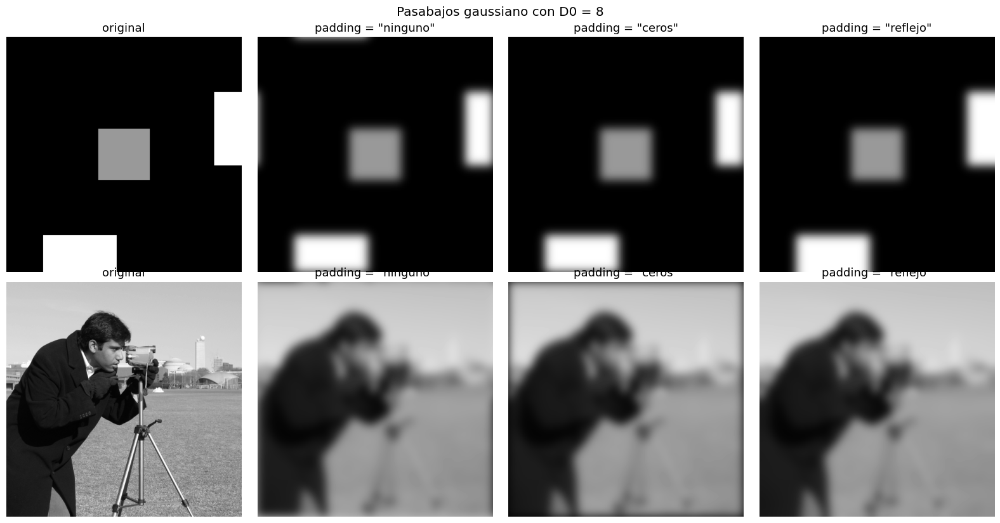

In [16]:
fig, ax = plt.subplots(2, 4, figsize=(16, 8.4))
for i, im in enumerate([bloques, cam]):
    ax[i, 0].imshow(im, vmin=0, vmax=1)
    ax[i, 0].set_title("original")
    for j, modo in enumerate(["ninguno", "ceros", "reflejo"], start=1):
        ax[i, j].imshow(filtrar(im, pb_gauss, padding=modo, D0=8), vmin=0, vmax=1)
        ax[i, j].set_title(f"padding = \"{modo}\"")
for a in ax.ravel():
    a.axis("off")
fig.suptitle("Pasabajos gaussiano con D0 = 8")
fig.tight_layout()
guardar(fig, "eq_padding_modos")
plt.show()

### 1.7 ✏️ Explora: convolución espacial vs. FFT

Cambia la imagen, el tamaño del kernel y el padding. Observa la diferencia entre ambos caminos.

In [17]:
@interact(imagen=widgets.Dropdown(options=opciones_imagenes(), value="camera"),
          k=widgets.IntSlider(value=21, min=3, max=81, step=2, continuous_update=False),
          kernel=widgets.ToggleButtons(options=["promedio", "gaussiano"]),
          padding=widgets.Checkbox(value=False, description="padding con ceros"))
def explorar_equivalencia(imagen, k, kernel, padding):
    f = cargar(imagen)
    h = np.ones((k, k)) / k**2 if kernel == "promedio" else kernel_gauss(k / 6)
    espacial = ndimage.convolve(f, h, mode="constant")
    via_fft = conv_fft(f, h, padding=padding)
    dif = np.abs(espacial - via_fft)
    ver([espacial, via_fft, dif],
        ["convolución espacial", "vía FFT", f"diferencia (máx = {dif.max():.1e})"],
        cmaps=["gray", "gray", "magma"], figsize=(13, 4.4))
    plt.show()

interactive(children=(Dropdown(description='imagen', options=('camera', 'moon', 'astronaut', 'coffee', 'chelse…

---
## 2. Filtros pasabajos

Todos dependen de la distancia al centro $D(u,v)=\sqrt{u^2+v^2}$ y de una **frecuencia de corte** $D_0$:

| Filtro | $H(u,v)$ | Característica |
|---|---|---|
| Ideal | $1$ si $D \le D_0$; $0$ si $D > D_0$ | corte abrupto, produce *ringing* |
| Butterworth de orden $n$ | $\dfrac{1}{1 + (D/D_0)^{2n}}$ | transición ajustable con $n$ |
| Gaussiano | $e^{-D^2/2D_0^2}$ | transición suave, sin *ringing* |

En Butterworth, $H(D_0) = 0.5$. En el gaussiano, $H(D_0) \approx 0.607$.
Con $n$ grande, Butterworth se acerca al ideal; con $n$ pequeño, se parece al gaussiano.

In [18]:
def pb_ideal(U, V, D0, n=None):
    return (np.hypot(U, V) <= D0).astype(float)


def pb_butterworth(U, V, D0, n=2):
    return 1 / (1 + (np.hypot(U, V) / D0) ** (2 * n))


# pb_gauss ya fue definido en la sección 1.3
PASABAJOS = {"ideal": pb_ideal, "butterworth": pb_butterworth, "gauss": pb_gauss}

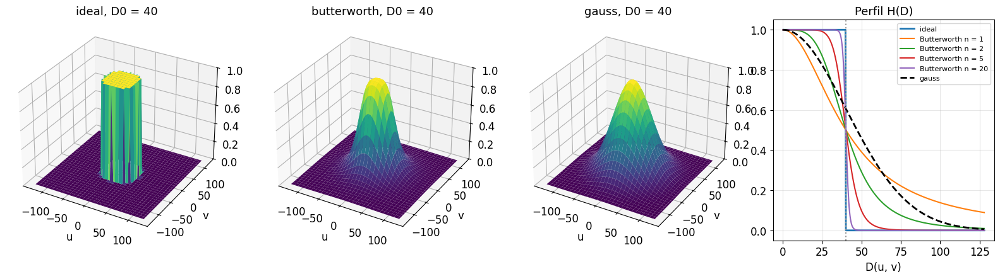

In [19]:
U, V = frecuencias((256, 256))
D0 = 40
fig = plt.figure(figsize=(16, 4.6))
for j, (nombre, Hf) in enumerate(PASABAJOS.items()):
    a = fig.add_subplot(1, 4, j + 1, projection="3d")
    a.plot_surface(U[::4, ::4], V[::4, ::4], Hf(U, V, D0)[::4, ::4], cmap="viridis", linewidth=0)
    a.set_title(f"{nombre}, D0 = {D0}")
    a.set_zlim(0, 1)
    a.set_xlabel("u")
    a.set_ylabel("v")
a = fig.add_subplot(1, 4, 4)
d = np.linspace(0, 128, 500)
a.plot(d, pb_ideal(d, 0, D0), label="ideal", lw=2)
for n in [1, 2, 5, 20]:
    a.plot(d, pb_butterworth(d, 0, D0, n), label=f"Butterworth n = {n}")
a.plot(d, pb_gauss(d, 0, D0), "k--", label="gauss", lw=2)
a.axvline(D0, color="0.6", ls=":")
a.set_xlabel("D(u, v)")
a.set_title("Perfil H(D)")
a.legend(fontsize=8)
a.grid(alpha=0.3)
fig.tight_layout()
guardar(fig, "pb_filtros")
plt.show()

### 2.1 El proceso completo, paso a paso

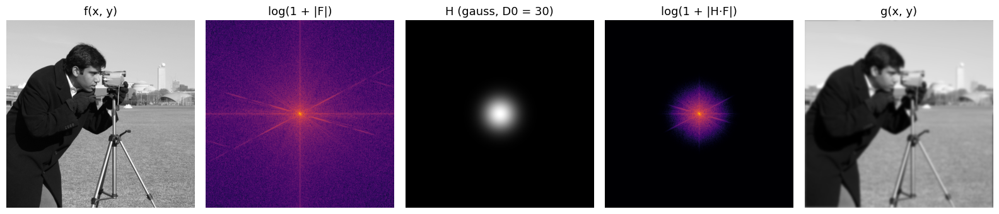

In [20]:
g, info = filtrar(cam, pb_gauss, padding="ninguno", detalles=True, D0=30)
fig = ver([cam, espectro(info["F"]), info["H"], espectro(info["G"]), g],
          ["f(x, y)", "log(1 + |F|)", "H (gauss, D0 = 30)", "log(1 + |H·F|)", "g(x, y)"],
          cmaps=["gray", "inferno", "gray", "inferno", "gray"], figsize=(16, 3.8))
guardar(fig, "pb_proceso")
plt.show()

### 2.2 Comparación de los tres filtros para distintos $D_0$

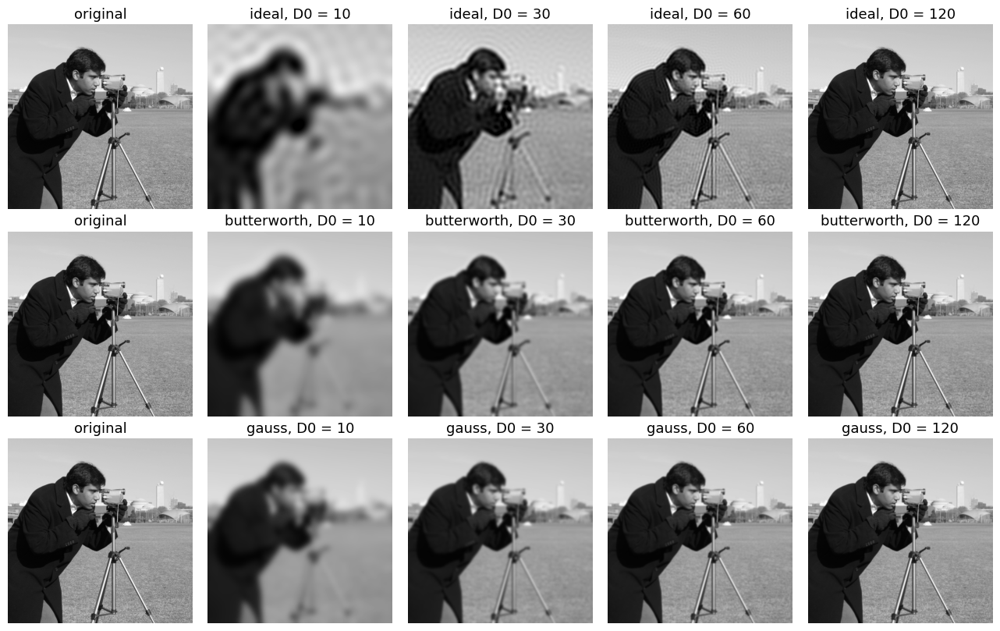

In [21]:
cortes = [10, 30, 60, 120]
fig, ax = plt.subplots(3, len(cortes) + 1, figsize=(13, 8.2))
for i, (nombre, Hf) in enumerate(PASABAJOS.items()):
    ax[i, 0].imshow(cam, vmin=0, vmax=1)
    ax[i, 0].set_title("original")
    for j, D0 in enumerate(cortes, start=1):
        ax[i, j].imshow(filtrar(cam, Hf, D0=D0, n=2), vmin=0, vmax=1)
        ax[i, j].set_title(f"{nombre}, D0 = {D0}")
for a in ax.ravel():
    a.axis("off")
fig.tight_layout()
guardar(fig, "pb_comparacion")
plt.show()

### 2.3 ¿Cuánta información queda dentro de $D_0$?

La **potencia** del espectro es $|F(u,v)|^2$. El porcentaje de potencia que deja pasar un pasabajos
ideal de radio $D_0$ es

$$\alpha = 100\,\frac{\sum_{D \le D_0} |F(u,v)|^2}{\sum_{u,v} |F(u,v)|^2}$$

Casi toda la energía está en las bajas frecuencias, pero el **detalle** vive en el pequeño
porcentaje restante.

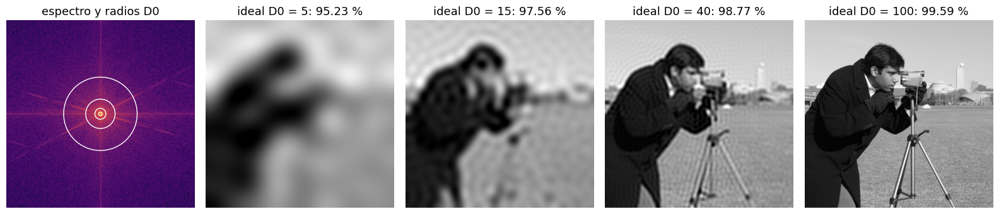

In [22]:
def potencia_retenida(f, D0):
    F = fft_centrada(f)
    U, V = frecuencias(f.shape)
    P = np.abs(F) ** 2
    return 100 * P[np.hypot(U, V) <= D0].sum() / P.sum()


radios = [5, 15, 40, 100]
fig, ax = plt.subplots(1, len(radios) + 1, figsize=(16, 3.8))
M, N = cam.shape
ax[0].imshow(espectro(fft_centrada(cam)), cmap="inferno", extent=[-N // 2, N // 2, M // 2, -M // 2])
for r in radios:
    ax[0].add_patch(plt.Circle((0, 0), r, fill=False, color="w", lw=1))
ax[0].set_title("espectro y radios D0")
for j, r in enumerate(radios, start=1):
    ax[j].imshow(filtrar(cam, pb_ideal, D0=r), vmin=0, vmax=1)
    ax[j].set_title(f"ideal D0 = {r}: {potencia_retenida(cam, r):.2f} %")
for a in ax:
    a.axis("off")
fig.tight_layout()
guardar(fig, "pb_energia")
plt.show()

### 2.4 *Ringing*: por qué el filtro ideal produce ondas

El filtro ideal en frecuencia es un cilindro. Su kernel espacial $h = \mathcal{F}^{-1}\{H\}$ es una
**sinc 2D**, con anillos que alternan entre positivo y negativo. Al convolucionar, cada borde de la
imagen se “copia” con esos anillos: eso es el *ringing*. El gaussiano no tiene anillos porque su
transformada es otra gaussiana.

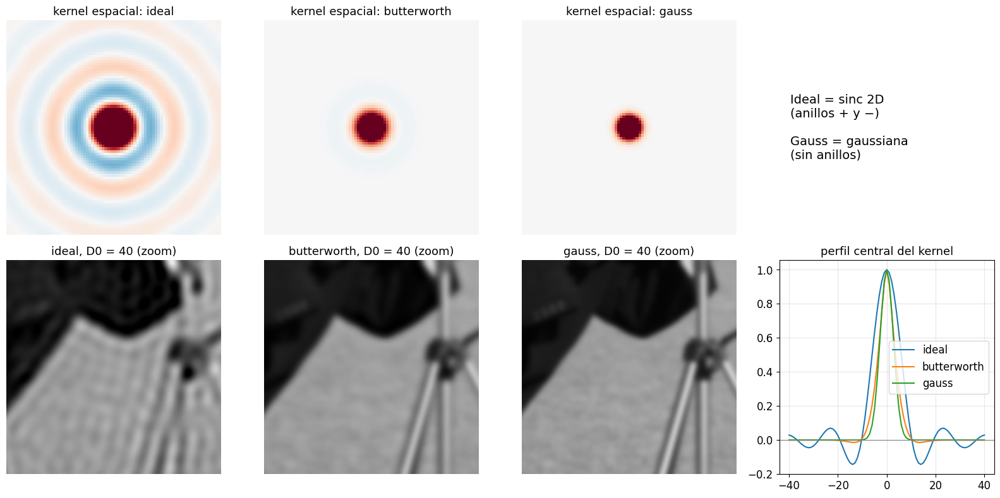

In [23]:
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
U, V = frecuencias((256, 256))
c = 128
for j, (nombre, Hf) in enumerate(PASABAJOS.items()):
    h = np.fft.fftshift(np.real(np.fft.ifft2(np.fft.ifftshift(Hf(U, V, 15, n=2)))))
    h = h / h.max()
    ax[0, j].imshow(h[c - 40:c + 41, c - 40:c + 41], cmap="RdBu_r", vmin=-0.3, vmax=0.3)
    ax[0, j].set_title(f"kernel espacial: {nombre}")
    ax[0, j].axis("off")
    ax[1, 3].plot(np.arange(-40, 41), h[c, c - 40:c + 41], label=nombre)
ax[1, 3].axhline(0, color="0.5", lw=0.8)
ax[1, 3].set_title("perfil central del kernel")
ax[1, 3].legend()
ax[1, 3].grid(alpha=0.3)
ax[0, 3].axis("off")
ax[0, 3].text(0.05, 0.5, "Ideal = sinc 2D\n(anillos + y −)\n\nGauss = gaussiana\n(sin anillos)",
              fontsize=14, va="center")
zona = (slice(250, 420), slice(150, 320))
for j, (nombre, Hf) in enumerate(PASABAJOS.items()):
    ax[1, j].imshow(filtrar(cam, Hf, D0=40, n=2)[zona], vmin=0, vmax=1)
    ax[1, j].set_title(f"{nombre}, D0 = 40 (zoom)")
    ax[1, j].axis("off")
fig.tight_layout()
guardar(fig, "pb_ringing")
plt.show()

### 2.5 ✏️ Explora los pasabajos

In [24]:
@interact(imagen=widgets.Dropdown(options=opciones_imagenes(), value="camera"),
          tipo=widgets.ToggleButtons(options=list(PASABAJOS)),
          D0=widgets.IntSlider(value=30, min=2, max=200, continuous_update=False),
          n=widgets.IntSlider(value=2, min=1, max=20, description="n (Butterworth)", continuous_update=False),
          padding=widgets.ToggleButtons(options=["reflejo", "ceros", "ninguno"]))
def explorar_pasabajos(imagen, tipo, D0, n, padding):
    f = cargar(imagen)
    g, info = filtrar(f, PASABAJOS[tipo], padding=padding, detalles=True, D0=D0, n=n)
    print(f"Potencia retenida (aprox. con filtro ideal): {potencia_retenida(f, D0):.2f} %")
    ver([f, info["H"], espectro(info["G"]), g], ["original", "H", "log(1 + |H·F|)", "resultado"],
        cmaps=["gray", "gray", "inferno", "gray"], figsize=(16, 4.4))
    plt.show()

interactive(children=(Dropdown(description='imagen', options=('camera', 'moon', 'astronaut', 'coffee', 'chelse…

---
## 3. Filtros pasaaltos

Un pasaaltos deja pasar lo que el pasabajos elimina:

$$H_{PA}(u,v) = 1 - H_{PB}(u,v)$$

Es la misma relación que vimos en el espacio, $h_{alto} = \delta - h_{bajo}$, porque
$\mathcal{F}\{\delta\} = 1$. Como $H_{PA}(0,0) = 0$, el resultado **pierde el brillo medio** (la DC) y
tiene valores negativos: hay que **normalizar** para mostrarlo.

In [25]:
def pa_ideal(U, V, D0, n=None):
    return 1 - pb_ideal(U, V, D0)


def pa_butterworth(U, V, D0, n=2):
    return 1 - pb_butterworth(U, V, D0, n)


def pa_gauss(U, V, D0, n=None):
    return 1 - pb_gauss(U, V, D0)


PASAALTOS = {"ideal": pa_ideal, "butterworth": pa_butterworth, "gauss": pa_gauss}

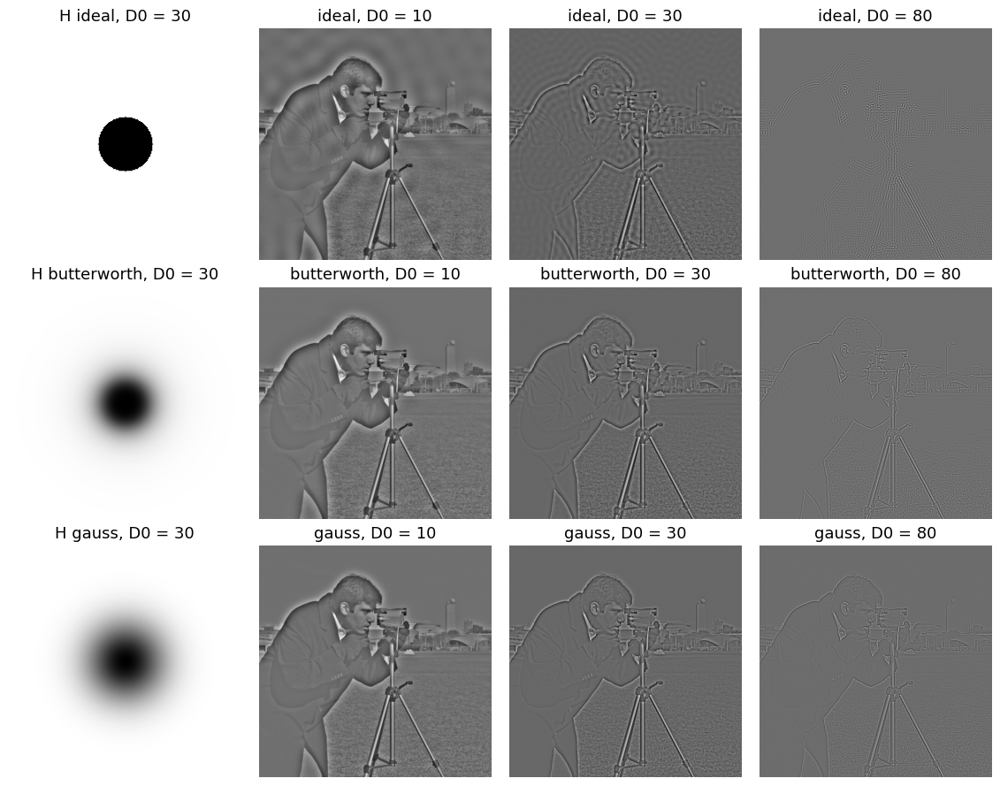

In [26]:
cortes = [10, 30, 80]
fig, ax = plt.subplots(3, len(cortes) + 1, figsize=(11.5, 9))
U, V = frecuencias((256, 256))
for i, (nombre, Hf) in enumerate(PASAALTOS.items()):
    ax[i, 0].imshow(Hf(U, V, 30, n=2), vmin=0, vmax=1)
    ax[i, 0].set_title(f"H {nombre}, D0 = 30")
    for j, D0 in enumerate(cortes, start=1):
        ax[i, j].imshow(normalizar(filtrar(cam, Hf, D0=D0, n=2)))
        ax[i, j].set_title(f"{nombre}, D0 = {D0}")
for a in ax.ravel():
    a.axis("off")
fig.tight_layout()
guardar(fig, "pa_comparacion")
plt.show()

### 3.1 Original = aproximación + detalle (ahora en frecuencia)

Como $H_{PB} + H_{PA} = 1$, se cumple $f = f_{PB} + f_{PA}$ exactamente.

máx |f - (f_PB + f_PA)| = 7.8e-16
máx |f_PA - (f - f_PB)| = 8.0e-16


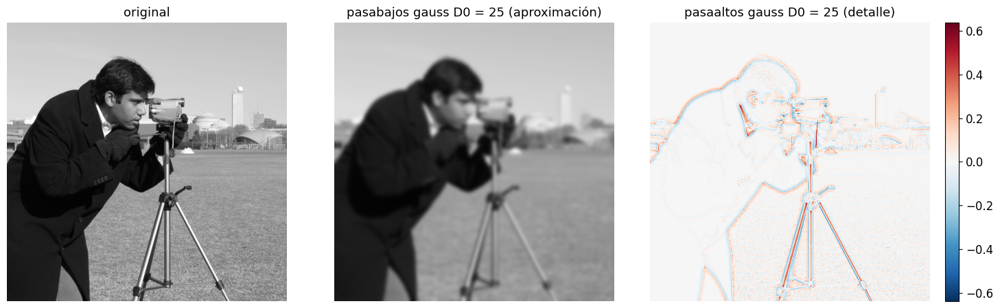

In [27]:
f_pb = filtrar(cam, pb_gauss, D0=25)
f_pa = filtrar(cam, pa_gauss, D0=25)
print(f"máx |f - (f_PB + f_PA)| = {np.abs(cam - (f_pb + f_pa)).max():.1e}")
print(f"máx |f_PA - (f - f_PB)| = {np.abs(f_pa - (cam - f_pb)).max():.1e}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].imshow(cam, vmin=0, vmax=1)
ax[0].set_title("original")
ax[1].imshow(f_pb, vmin=0, vmax=1)
ax[1].set_title("pasabajos gauss D0 = 25 (aproximación)")
lim = np.abs(f_pa).max()
im = ax[2].imshow(f_pa, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax[2].set_title("pasaaltos gauss D0 = 25 (detalle)")
fig.colorbar(im, ax=ax[2], fraction=0.046)
for a in ax:
    a.axis("off")
fig.tight_layout()
guardar(fig, "pa_descomposicion")
plt.show()

### 3.2 El Laplaciano en frecuencia

Derivar en el espacio equivale a multiplicar por la frecuencia. Para el Laplaciano
$\nabla^2 f = \partial^2 f/\partial x^2 + \partial^2 f/\partial y^2$:

$$H_{\nabla^2}(u,v) = -4\pi^2\left(\tilde u^2 + \tilde v^2\right)$$

donde $\tilde u = u/N$ y $\tilde v = v/M$ están en ciclos por píxel. Para **realzar** la imagen se
resta el Laplaciano, como en la clase de pasaaltos:

$$g = f - c\,\nabla^2 f \quad\Longleftrightarrow\quad G = \left[1 + c\,4\pi^2(\tilde u^2+\tilde v^2)\right] F$$

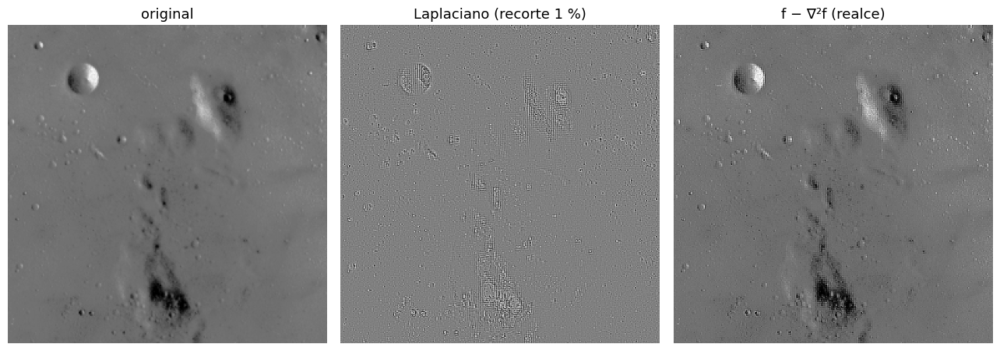

In [28]:
def laplaciano(U, V, forma):
    # forma = tamaño de la imagen original, para pasar de ciclos/imagen a ciclos/píxel
    M, N = forma
    return -4 * np.pi**2 * ((U / N) ** 2 + (V / M) ** 2)


def realce_laplaciano(U, V, forma, c=1.0):
    return 1 - c * laplaciano(U, V, forma)


luna = cargar("moon")
lap = filtrar(luna, laplaciano, padding="reflejo", forma=luna.shape)
realzada = filtrar(luna, realce_laplaciano, padding="reflejo", forma=luna.shape, c=1.0)

fig = ver([luna, normalizar(lap, recorte=1), np.clip(realzada, 0, 1)],
          ["original", "Laplaciano (recorte 1 %)", "f − ∇²f (realce)"], figsize=(13, 4.6))
guardar(fig, "pa_laplaciano")
plt.show()

### 3.3 Máscara de desenfoque y énfasis de altas frecuencias

En el espacio vimos *unsharp masking*: $g = f + k\,(f - f_{suave})$. En frecuencia es simplemente:

$$H_{\text{énfasis}}(u,v) = k_1 + k_2\,H_{PA}(u,v)$$

- $k_1 = 1,\ k_2 = 1$: *unsharp masking*. Con $k_2 > 1$: *high-boost*.
- $k_1 < 1$ reduce la DC y el contraste global; $k_2$ realza el detalle.

Una combinación clásica es $k_1 = 0.5$, $k_2 = 0.75$ seguida de una ecualización de histograma.

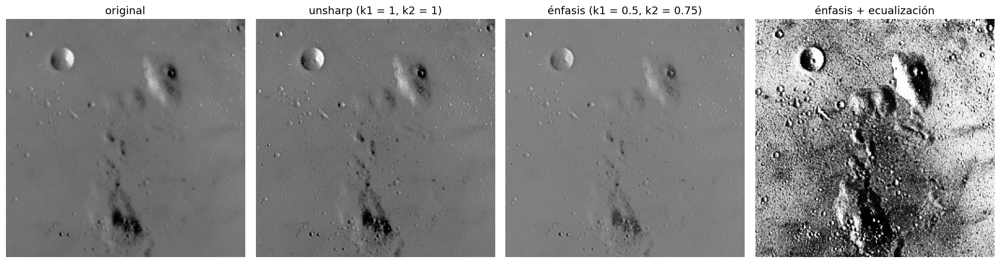

In [29]:
def enfasis(U, V, D0, k1=0.5, k2=0.75):
    return k1 + k2 * pa_gauss(U, V, D0)


from skimage import exposure

g_unsharp = filtrar(luna, enfasis, D0=30, k1=1, k2=1)
g_enfasis = filtrar(luna, enfasis, D0=30, k1=0.5, k2=0.75)
g_ecualizada = exposure.equalize_hist(normalizar(g_enfasis))

fig = ver([luna, np.clip(g_unsharp, 0, 1), normalizar(g_enfasis), g_ecualizada],
          ["original", "unsharp (k1 = 1, k2 = 1)", "énfasis (k1 = 0.5, k2 = 0.75)", "énfasis + ecualización"],
          figsize=(17, 4.6))
guardar(fig, "pa_enfasis")
plt.show()

### 3.4 ✏️ Explora los pasaaltos y el énfasis

In [30]:
@interact(imagen=widgets.Dropdown(options=opciones_imagenes(), value="moon"),
          tipo=widgets.ToggleButtons(options=list(PASAALTOS)),
          D0=widgets.IntSlider(value=30, min=2, max=200, continuous_update=False),
          n=widgets.IntSlider(value=2, min=1, max=20, description="n (Butterworth)", continuous_update=False),
          k1=widgets.FloatSlider(value=0.5, min=0, max=2, step=0.05, continuous_update=False),
          k2=widgets.FloatSlider(value=0.75, min=0, max=4, step=0.05, continuous_update=False))
def explorar_pasaaltos(imagen, tipo, D0, n, k1, k2):
    f = cargar(imagen)
    detalle = filtrar(f, PASAALTOS[tipo], D0=D0, n=n)
    realce = k1 * f + k2 * detalle      # equivale a H = k1 + k2·H_PA
    ver([f, normalizar(detalle), np.clip(realce, 0, 1)],
        ["original", f"pasaaltos {tipo} (normalizado)", f"k1·f + k2·detalle"], figsize=(14, 4.6))
    plt.show()

interactive(children=(Dropdown(description='imagen', index=1, options=('camera', 'moon', 'astronaut', 'coffee'…

---
## 4. Filtros rechazabanda y pasabanda

Atenúan (o dejan pasar) un **anillo** de frecuencias de radio $C_0$ y ancho $W$:

| Rechazabanda | $H_{RB}(u,v)$ |
|---|---|
| Ideal | $0$ si $C_0 - \tfrac{W}{2} \le D \le C_0 + \tfrac{W}{2}$; $1$ en otro caso |
| Butterworth | $\dfrac{1}{1 + \left[\dfrac{D\,W}{D^2 - C_0^2}\right]^{2n}}$ |
| Gaussiano | $1 - e^{-\left[\frac{D^2 - C_0^2}{D\,W}\right]^2}$ |

y el pasabanda es $H_{PBanda} = 1 - H_{RB}$.

In [31]:
def rb_ideal(U, V, C0, W, n=None):
    D = np.hypot(U, V)
    return 1 - ((D >= C0 - W / 2) & (D <= C0 + W / 2)).astype(float)


def rb_butterworth(U, V, C0, W, n=2):
    D = np.hypot(U, V)
    with np.errstate(divide="ignore", invalid="ignore"):
        H = 1 / (1 + (D * W / (D**2 - C0**2)) ** (2 * n))
    return np.nan_to_num(H, nan=0.0)


def rb_gauss(U, V, C0, W, n=None):
    D = np.hypot(U, V) + 1e-9
    return 1 - np.exp(-(((D**2 - C0**2) / (D * W)) ** 2))


def pasabanda(rechazo):
    return lambda U, V, **p: 1 - rechazo(U, V, **p)


RECHAZABANDA = {"ideal": rb_ideal, "butterworth": rb_butterworth, "gauss": rb_gauss}

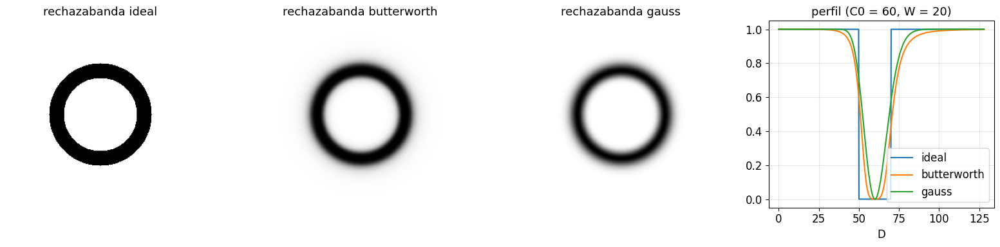

In [32]:
U, V = frecuencias((256, 256))
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for j, (nombre, Hf) in enumerate(RECHAZABANDA.items()):
    ax[j].imshow(Hf(U, V, C0=60, W=20), vmin=0, vmax=1)
    ax[j].set_title(f"rechazabanda {nombre}")
    ax[j].axis("off")
d = np.linspace(0, 128, 600)
for nombre, Hf in RECHAZABANDA.items():
    ax[3].plot(d, Hf(d, 0, C0=60, W=20), label=nombre)
ax[3].set_title("perfil (C0 = 60, W = 20)")
ax[3].set_xlabel("D")
ax[3].legend()
ax[3].grid(alpha=0.3)
fig.tight_layout()
guardar(fig, "banda_filtros")
plt.show()

### 4.1 Ruido periódico en anillo

Esta imagen tiene seis ondas sinusoidales de la **misma frecuencia** en distintas orientaciones. En el
espectro aparecen como 12 puntos sobre un círculo, y un rechazabanda las elimina de una vez.

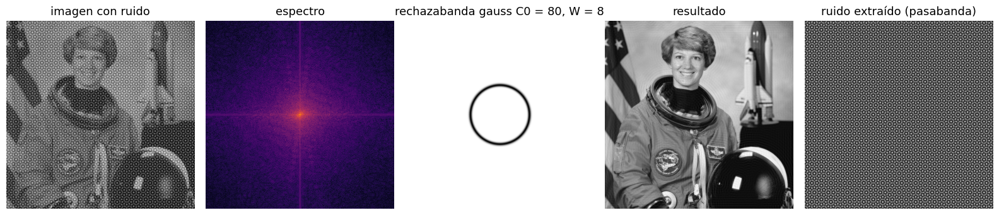

In [33]:
anillo = cargar("ruido_anillo.png")
C0, W = 80, 8
g, info = filtrar(anillo, rb_gauss, padding="ninguno", detalles=True, C0=C0, W=W)
ruido = filtrar(anillo, pasabanda(rb_gauss), padding="ninguno", C0=C0, W=W)

fig = ver([anillo, espectro(info["F"]), info["H"], g, normalizar(ruido)],
          ["imagen con ruido", "espectro", f"rechazabanda gauss C0 = {C0}, W = {W}", "resultado", "ruido extraído (pasabanda)"],
          cmaps=["gray", "inferno", "gray", "gray", "gray"], figsize=(16, 3.8))
guardar(fig, "banda_anillo")
plt.show()

### 4.2 Pasabanda: una imagen es la suma de sus bandas

Separamos la imagen en tres bandas con filtros ideales. Como cubren todo el espectro sin traslaparse,
la suma reconstruye la original.

máx |f - suma de bandas| = 7.8e-16


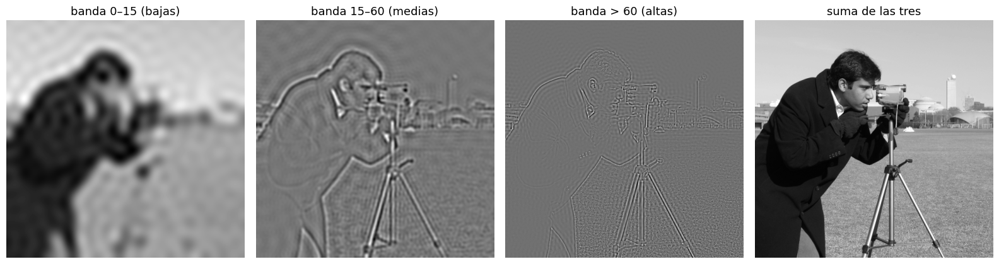

In [34]:
def banda_ideal(U, V, r1, r2):
    D = np.hypot(U, V)
    return ((D >= r1) & (D < r2)).astype(float)


limites = [(0, 15), (15, 60), (60, 1e9)]
bandas = [filtrar(cam, banda_ideal, padding="reflejo", r1=a, r2=b) for a, b in limites]
print(f"máx |f - suma de bandas| = {np.abs(cam - sum(bandas)).max():.1e}")

fig = ver([bandas[0], normalizar(bandas[1]), normalizar(bandas[2]), sum(bandas)],
          ["banda 0–15 (bajas)", "banda 15–60 (medias)", "banda > 60 (altas)", "suma de las tres"],
          figsize=(16, 4.4))
guardar(fig, "banda_descomposicion")
plt.show()

### 4.3 ✏️ Explora el rechazabanda y el pasabanda

In [35]:
@interact(imagen=widgets.Dropdown(options=opciones_imagenes(), value="ruido_anillo.png"),
          tipo=widgets.ToggleButtons(options=list(RECHAZABANDA)),
          modo=widgets.ToggleButtons(options=["rechazabanda", "pasabanda"]),
          C0=widgets.IntSlider(value=80, min=1, max=250, continuous_update=False),
          W=widgets.IntSlider(value=8, min=1, max=100, continuous_update=False),
          n=widgets.IntSlider(value=2, min=1, max=10, description="n (Butterworth)", continuous_update=False))
def explorar_bandas(imagen, tipo, modo, C0, W, n):
    f = cargar(imagen)
    Hf = RECHAZABANDA[tipo] if modo == "rechazabanda" else pasabanda(RECHAZABANDA[tipo])
    g, info = filtrar(f, Hf, padding="ninguno", detalles=True, C0=C0, W=W, n=n)
    salida = g if modo == "rechazabanda" else normalizar(g)
    ver([f, espectro(info["F"]), info["H"], salida], ["original", "espectro", "H", "resultado"],
        cmaps=["gray", "inferno", "gray", "gray"], figsize=(16, 4.4))
    plt.show()

interactive(children=(Dropdown(description='imagen', index=12, options=('camera', 'moon', 'astronaut', 'coffee…

---
## 5. Filtros *notch*: eliminar ruido periódico

Si el ruido es una o pocas ondas sinusoidales, en el espectro aparece como **pares de puntos
brillantes** simétricos respecto del origen (como en la radiografía de la clase anterior). En vez de
un anillo completo, conviene eliminar **solo esos puntos**.

Un *notch* de rechazo es un producto de pasaaltos **centrados en cada punto y en su simétrico**:

$$H_{NR}(u,v) = \prod_{k=1}^{Q} H_k(u,v)\,H_{-k}(u,v)$$

Con Butterworth:

$$H_k = \frac{1}{1 + \left[D_0/D_k\right]^{2n}},\qquad
D_k = \sqrt{(u-u_k)^2 + (v-v_k)^2},\qquad D_{-k} = \sqrt{(u+u_k)^2 + (v+v_k)^2}$$

> El par simétrico $(-u_k, -v_k)$ **no es opcional**: sin él, $H$ no es simétrico y la salida deja de
> ser real (sección 1.5).

In [36]:
def notch_rechazo(U, V, centros, D0=6, n=2, tipo="butterworth"):
    H = np.ones(U.shape)
    for uk, vk in centros:
        for s in (1, -1):                       # el punto y su simétrico
            Dk = np.hypot(U - s * uk, V - s * vk)
            if tipo == "butterworth":
                with np.errstate(divide="ignore"):
                    H *= 1 / (1 + (D0 / Dk) ** (2 * n))
            else:
                H *= 1 - np.exp(-Dk**2 / (2 * D0**2))
    return H


def notch_paso(U, V, **p):
    return 1 - notch_rechazo(U, V, **p)


def buscar_peaks(f, cantidad=4, radio_min=10, ventana=15):
    # Busca máximos locales del espectro que sobresalen de su vecindario, fuera de la zona central.
    # Devuelve un punto (u, v) por cada par simétrico.
    S = espectro(fft_centrada(f))
    U, V = frecuencias(f.shape)
    realce = S - ndimage.median_filter(S, size=ventana)
    es_max = realce == ndimage.maximum_filter(realce, size=ventana)
    candidato = es_max & (np.hypot(U, V) > radio_min) & ((V > 0) | ((V == 0) & (U > 0)))
    orden = np.argsort(realce[candidato])[::-1][:cantidad]
    return [(float(u), float(v)) for u, v in zip(U[candidato][orden], V[candidato][orden])]


periodico = cargar("ruido_periodico.png")
centros = buscar_peaks(periodico, cantidad=2)
print("Peaks encontrados (u, v):", centros)

Peaks encontrados (u, v): [(-20.0, 90.0), (48.0, 36.0)]


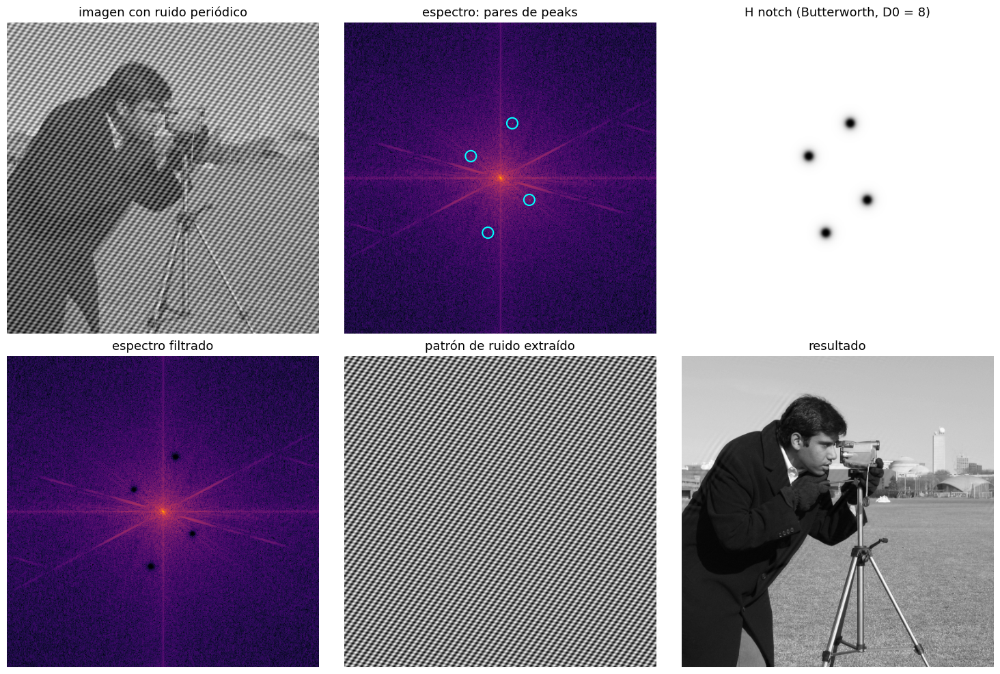

In [37]:
def marcar_peaks(ax, centros, forma, color="cyan"):
    for uk, vk in centros:
        for s in (1, -1):
            ax.add_patch(plt.Circle((s * uk, s * vk), 9, fill=False, color=color, lw=1.5))


M, N = periodico.shape
ext = [-N // 2, N // 2, M // 2, -M // 2]
g, info = filtrar(periodico, notch_rechazo, padding="ninguno", detalles=True, centros=centros, D0=8, n=2)
patron = filtrar(periodico, notch_paso, padding="ninguno", centros=centros, D0=8, n=2)

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
ax[0, 0].imshow(periodico)
ax[0, 0].set_title("imagen con ruido periódico")
ax[0, 1].imshow(espectro(info["F"]), cmap="inferno", extent=ext)
marcar_peaks(ax[0, 1], centros, periodico.shape)
ax[0, 1].set_title("espectro: pares de peaks")
ax[0, 2].imshow(info["H"], extent=ext)
ax[0, 2].set_title("H notch (Butterworth, D0 = 8)")
ax[1, 0].imshow(espectro(info["G"]), cmap="inferno", extent=ext)
ax[1, 0].set_title("espectro filtrado")
ax[1, 1].imshow(normalizar(patron))
ax[1, 1].set_title("patrón de ruido extraído")
ax[1, 2].imshow(np.clip(g, 0, 1))
ax[1, 2].set_title("resultado")
for a in ax.ravel():
    a.axis("off")
fig.tight_layout()
guardar(fig, "notch_demo")
plt.show()

**¿Por qué `padding="ninguno"` en los *notch*?** El ruido es periódico **dentro de la imagen**: completa
ciclos enteros y por eso cae en puntos exactos del espectro. Si rellenamos, esa periodicidad se rompe
y el punto se “derrama” en una cruz, lo que obliga a usar *notch* más anchos.

**Notch vs. rechazabanda:** el rechazabanda elimina un anillo completo, incluida información útil de
la imagen a esa frecuencia. El *notch* quita solo lo necesario.

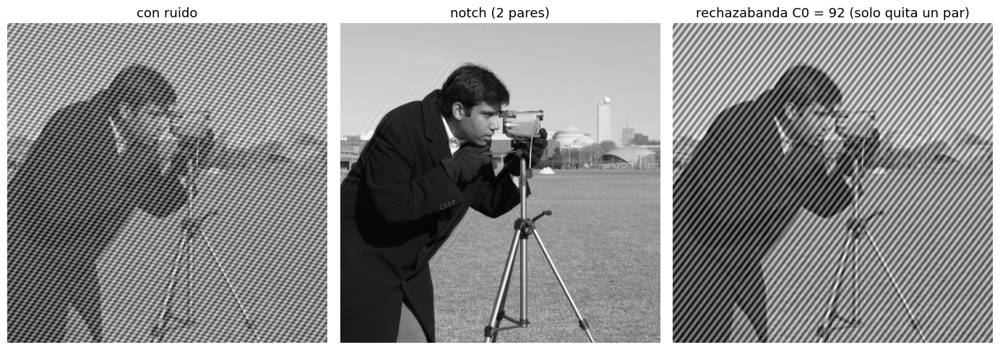

In [38]:
radio = np.hypot(*centros[0])
g_banda = filtrar(periodico, rb_gauss, padding="ninguno", C0=radio, W=10)
fig = ver([periodico, np.clip(g, 0, 1), np.clip(g_banda, 0, 1)],
          ["con ruido", "notch (2 pares)", f"rechazabanda C0 = {radio:.0f} (solo quita un par)"], figsize=(14, 4.8))
guardar(fig, "notch_vs_banda")
plt.show()

### 5.1 ✏️ Explora el *notch*

Puedes usar la búsqueda automática o escribir tus propios centros en `CENTROS_MANUALES`
(en ciclos por imagen, como en los ejes del espectro).

In [39]:
CENTROS_MANUALES = []   # ✏️ p. ej. [(48, 36), (-20, 90)]


@interact(imagen=widgets.Dropdown(options=opciones_imagenes(), value="ruido_periodico.png"),
          cantidad=widgets.IntSlider(value=2, min=0, max=8, description="peaks auto", continuous_update=False),
          D0=widgets.IntSlider(value=8, min=1, max=40, continuous_update=False),
          n=widgets.IntSlider(value=2, min=1, max=10, description="n (Butterworth)", continuous_update=False),
          tipo=widgets.ToggleButtons(options=["butterworth", "gauss"]))
def explorar_notch(imagen, cantidad, D0, n, tipo):
    f = cargar(imagen)
    centros = CENTROS_MANUALES or buscar_peaks(f, cantidad=cantidad)
    print("Centros usados (u, v):", [(round(u, 1), round(v, 1)) for u, v in centros])
    g, info = filtrar(f, notch_rechazo, padding="ninguno", detalles=True, centros=centros, D0=D0, n=n, tipo=tipo)
    M, N = f.shape
    fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
    ax[0].imshow(f)
    ax[0].set_title("original")
    ax[1].imshow(espectro(info["F"]), cmap="inferno", extent=[-N // 2, N // 2, M // 2, -M // 2])
    marcar_peaks(ax[1], centros, f.shape)
    ax[1].set_title("espectro")
    ax[2].imshow(espectro(info["G"]), cmap="inferno", extent=[-N // 2, N // 2, M // 2, -M // 2])
    ax[2].set_title("espectro filtrado")
    ax[3].imshow(np.clip(g, 0, 1))
    ax[3].set_title("resultado")
    for a in (ax[0], ax[3]):
        a.axis("off")
    fig.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='imagen', index=13, options=('camera', 'moon', 'astronaut', 'coffee…

---
## 6. Filtro homomórfico

Una imagen se puede modelar como el **producto** de la iluminación y la reflectancia:

$$f(x,y) = i(x,y)\cdot r(x,y)$$

- $i$: iluminación. Varía **lento** (bajas frecuencias).
- $r$: reflectancia (los objetos y sus bordes). Varía **rápido** (altas frecuencias).

La Fourier de un producto **no** separa sus factores, pero el logaritmo convierte el producto en suma:

$$z = \ln f = \ln i + \ln r \;\Rightarrow\; Z = F_i + F_r$$

Proceso: $\ \ln \rightarrow \text{FFT} \rightarrow H \rightarrow \text{IFFT} \rightarrow \exp$.
El filtro **atenúa** las bajas ($\gamma_L < 1$) y **amplifica** las altas ($\gamma_H > 1$):

$$H(u,v) = (\gamma_H - \gamma_L)\left[1 - e^{-c\,D^2/D_0^2}\right] + \gamma_L$$

Así se comprime el rango de la iluminación y se realza el contraste local.

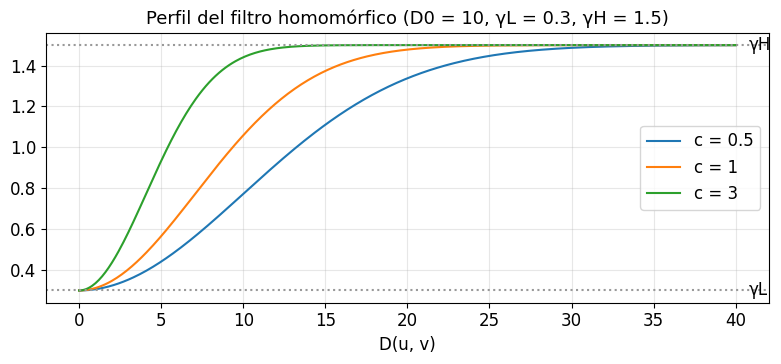

In [40]:
def H_homomorfico(U, V, D0=10, gL=0.3, gH=1.5, c=1.0):
    return (gH - gL) * (1 - np.exp(-c * (U**2 + V**2) / D0**2)) + gL


def homomorfico(f, eps=0.01, padding="reflejo", **param):
    z = np.log(f + eps)
    s = filtrar(z, H_homomorfico, padding=padding, **param)
    return normalizar(np.exp(s), recorte=0.5)   # el recorte evita que unos pocos brillos dominen


d = np.linspace(0, 40, 400)
fig, ax = plt.subplots(figsize=(8, 3.8))
for c in [0.5, 1, 3]:
    ax.plot(d, H_homomorfico(d, 0, D0=10, gL=0.3, gH=1.5, c=c), label=f"c = {c}")
ax.axhline(0.3, color="0.6", ls=":")
ax.axhline(1.5, color="0.6", ls=":")
ax.text(40.8, 0.3, "γL", va="center")
ax.text(40.8, 1.5, "γH", va="center")
ax.set_xlabel("D(u, v)")
ax.set_title("Perfil del filtro homomórfico (D0 = 10, γL = 0.3, γH = 1.5)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
guardar(fig, "homo_filtro")
plt.show()

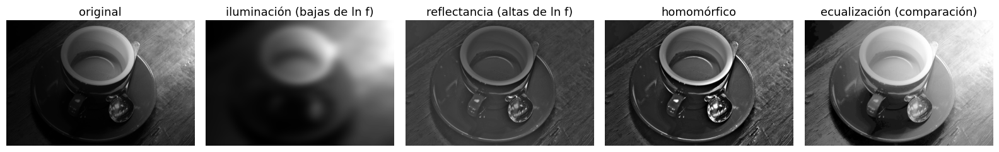

In [41]:
oscura = cargar("iluminacion_no_uniforme.png")
z = np.log(oscura + 0.01)
ilum = normalizar(np.exp(filtrar(z, pb_gauss, D0=6)))      # estimación de la iluminación
refl = normalizar(np.exp(filtrar(z, pa_gauss, D0=6)))      # estimación de la reflectancia
resultado = homomorfico(oscura, D0=10, gL=0.3, gH=1.5, c=1.0)

fig = ver([oscura, ilum, refl, resultado, exposure.equalize_hist(oscura)],
          ["original", "iluminación (bajas de ln f)", "reflectancia (altas de ln f)", "homomórfico", "ecualización (comparación)"],
          figsize=(16, 3.4))
guardar(fig, "homo_resultado")
plt.show()

### 6.1 ✏️ Explora el homomórfico

Prueba también con `page` (un documento con iluminación desigual).

In [42]:
@interact(imagen=widgets.Dropdown(options=opciones_imagenes(), value="iluminacion_no_uniforme.png"),
          D0=widgets.IntSlider(value=10, min=1, max=150, continuous_update=False),
          gL=widgets.FloatSlider(value=0.3, min=0.05, max=1.0, step=0.05, description="γL", continuous_update=False),
          gH=widgets.FloatSlider(value=1.5, min=1.0, max=4.0, step=0.1, description="γH", continuous_update=False),
          c=widgets.FloatSlider(value=1.0, min=0.1, max=5, step=0.1, continuous_update=False))
def explorar_homomorfico(imagen, D0, gL, gH, c):
    f = cargar(imagen)
    ver([f, homomorfico(f, D0=D0, gL=gL, gH=gH, c=c)], ["original", "homomórfico"], figsize=(12, 5))
    plt.show()

interactive(children=(Dropdown(description='imagen', index=11, options=('camera', 'moon', 'astronaut', 'coffee…

---
## 7. Actividad final: eliminar ruido periódico

La imagen `actividad_ruido.png` está contaminada con **interferencia periódica**. Tu objetivo es
recuperar la imagen lo mejor posible usando lo visto en clase.

**Pasos sugeridos**

1. Carga la imagen y observa su espectro. ¿Cuántos pares de peaks ves? ¿Dónde están (en $u, v$)?
2. Diseña un filtro *notch* de rechazo (Butterworth o gaussiano). Decide los centros, $D_0$ y $n$.
3. Aplica el filtro y muestra: espectro filtrado, patrón de ruido extraído y resultado.
4. Compara tu resultado con un pasabajos y con un rechazabanda. ¿Cuál conserva mejor el detalle?

**Preguntas para discutir**

- ¿Qué pasa si filtras solo uno de los dos puntos de un par? Revisa la parte imaginaria.
- Uno de los peaks tiene una “cruz” alrededor. ¿Por qué? ¿Cómo lo manejarías?
- ¿Qué valor de $D_0$ es demasiado grande? ¿Cómo se nota en la imagen?

Puedes usar todas las funciones de este cuaderno (`cargar`, `espectro`, `fft_centrada`, `frecuencias`,
`filtrar`, `notch_rechazo`, `buscar_peaks`, `ver`, ...).

In [48]:
# 1. Cargar la imagen y observar su espectro

In [49]:
# 2. Diseñar el filtro notch

In [50]:
# 3. Aplicar el filtro y mostrar los resultados

In [51]:
# 4. Comparar con pasabajos y rechazabanda